# Course 3: Ten Years of Deep Learning Ideas
## Session 10: Deep reinforcement learning, from AlphaGo to world models

**Goal:** write CartPole from its equations, train an agent on it with PPO and GAE, test what PPO's clipping does, and play tic-tac-toe with Monte Carlo tree search.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. Setup
No `gym` here: section 2 writes the environment from its equations, so you can see that an RL environment is just a function from (state, action) to (next state, reward, done).

In [1]:
import math, random, time
import numpy as np
import torch, torch.nn as nn
import matplotlib.pyplot as plt

torch.set_num_threads(1)                    # small models run fastest on one thread
torch.manual_seed(0); np.random.seed(0)

### 2. CartPole from the classic equations
A pole is hinged on a cart that moves left or right on a track. Each step the agent pushes the cart with a force of +10 or −10 newtons, and gets a reward of 1 for every step the pole stays up. The episode ends when the pole leans more than 12° or the cart leaves the track (|x| > 2.4), or after 500 steps. The constants and equations are the classic ones used by Gym's `CartPole-v1`, integrated with Euler steps of 0.02 s:

$\ddot\theta = \dfrac{g \sin\theta - \cos\theta \cdot \text{temp}}{l\,(4/3 - m_p \cos^2\theta / M)}$, with $\text{temp} = \dfrac{F + m_p l \dot\theta^2 \sin\theta}{M}$ and $\ddot x = \text{temp} - \dfrac{m_p l \ddot\theta \cos\theta}{M}$,

where $M = m_c + m_p$ is the total mass and $l$ is half the pole's length. We run many carts at once with NumPy arrays; a cart that finishes is reset at once.

In [2]:
class CartPole:
    g, m_cart, m_pole, half_len, force, tau = 9.8, 1.0, 0.1, 0.5, 10.0, 0.02
    x_max, theta_max, max_steps = 2.4, 12 * math.pi / 180, 500

    def __init__(self, n, seed=0):
        self.n, self.rng = n, np.random.default_rng(seed)
        self.s = self.rng.uniform(-0.05, 0.05, (n, 4)); self.t = np.zeros(n, dtype=int)   # state: x, x_dot, theta, theta_dot

    def step(self, a):
        x, x_dot, th, th_dot = self.s.T
        f = np.where(a == 1, self.force, -self.force)
        cos, sin = np.cos(th), np.sin(th)
        total, pml = self.m_cart + self.m_pole, self.m_pole * self.half_len
        temp = (f + pml * th_dot ** 2 * sin) / total
        th_acc = (self.g * sin - cos * temp) / (self.half_len * (4 / 3 - self.m_pole * cos ** 2 / total))
        x_acc = temp - pml * th_acc * cos / total
        self.s = np.stack([x + self.tau * x_dot, x_dot + self.tau * x_acc, th + self.tau * th_dot, th_dot + self.tau * th_acc], 1)
        self.t += 1
        term = (np.abs(self.s[:, 0]) > self.x_max) | (np.abs(self.s[:, 2]) > self.theta_max)    # the pole fell or the cart left
        trunc = (self.t >= self.max_steps) & ~term                                             # time limit reached
        final = self.s.copy()                                                                  # last state before any reset
        done = term | trunc
        self.s[done] = self.rng.uniform(-0.05, 0.05, (done.sum(), 4)); self.t[done] = 0
        return self.s.copy(), np.ones(self.n), term, trunc, final

def average_return(policy, n_episodes=200, seed=1):
    env, total, returns = CartPole(n_episodes, seed), np.zeros(n_episodes), []
    alive = np.ones(n_episodes, bool)
    while alive.any():
        s, r, term, trunc, _ = env.step(policy(env.s))
        total += r * alive; alive &= ~(term | trunc)
    return total.mean()

rng = np.random.default_rng(0)
print(f"random pushes:                      average return {average_return(lambda s: rng.integers(0, 2, len(s))):.1f}")
print(f"push toward the side the pole leans: average return {average_return(lambda s: (s[:, 2] + 0.5 * s[:, 3] > 0).astype(int)):.1f}")

random pushes:                      average return 22.7
push toward the side the pole leans: average return 500.0


### 3. Actor-critic and generalized advantage estimation
The **actor** outputs probabilities for the two actions; the **critic** estimates the value $V(s)$, the expected sum of future rewards. GAE (Schulman et al. 2016) builds the advantage from one-step errors $\delta_t = r_t + \gamma V(s_{t+1}) - V(s_t)$:

$\hat A_t = \delta_t + \gamma\lambda\,\delta_{t+1} + (\gamma\lambda)^2\,\delta_{t+2} + \dots$

$\lambda = 0$ uses one step (low variance, more bias); $\lambda = 1$ uses the whole return (no bias from $V$, high variance). The check: with $\lambda = 1$ and no episode end, GAE equals the discounted return minus $V(s_t)$.

In [3]:
def gae(rewards, values, dones, last_value, gamma=0.99, lam=0.95):
    # rewards, values, dones: (n_steps, n_envs); dones[t] = 1 if the episode ended at step t
    adv, running = torch.zeros_like(rewards), torch.zeros_like(last_value)
    for t in reversed(range(len(rewards))):
        next_value = last_value if t == len(rewards) - 1 else values[t + 1]
        delta = rewards[t] + gamma * next_value * (1 - dones[t]) - values[t]
        running = delta + gamma * lam * (1 - dones[t]) * running
        adv[t] = running
    return adv

r, v = torch.tensor([[1.0], [2.0], [3.0]]), torch.tensor([[0.5], [0.4], [0.3]]); last = torch.tensor([0.2])
g = 0.9; mc = torch.tensor([1 + g * 2 + g ** 2 * 3 + g ** 3 * 0.2, 2 + g * 3 + g ** 2 * 0.2, 3 + g * 0.2])
print("GAE with lambda = 1:", gae(r, v, torch.zeros(3, 1), last, gamma=g, lam=1.0).flatten().numpy().round(4))
print("return minus V:     ", (mc - v.flatten()).numpy().round(4))

def layer(n_in, n_out, std=math.sqrt(2)):            # orthogonal initialization, one of PPO's implementation details
    l = nn.Linear(n_in, n_out); nn.init.orthogonal_(l.weight, std); nn.init.zeros_(l.bias); return l

class ActorCritic(nn.Module):
    def __init__(self, h=64):
        super().__init__()
        self.pi = nn.Sequential(layer(4, h), nn.Tanh(), layer(h, h), nn.Tanh(), layer(h, 2, 0.01))
        self.v = nn.Sequential(layer(4, h), nn.Tanh(), layer(h, h), nn.Tanh(), layer(h, 1, 1.0))

GAE with lambda = 1: [4.8758 4.462  2.88  ]
return minus V:      [4.8758 4.462  2.88  ]


### 4. PPO
Each update collects 16 × 64 = 1,024 steps, computes advantages, then takes 4 passes over the data in minibatches of 256, maximizing the clipped objective (Schulman et al. 2017):

$L^{\text{CLIP}} = \mathbb{E}\left[\min\left(r_t \hat A_t,\ \text{clip}(r_t, 1-\varepsilon, 1+\varepsilon)\,\hat A_t\right)\right]$, with $r_t = \pi_\theta(a_t \mid s_t) / \pi_{\text{old}}(a_t \mid s_t)$.

Several implementation details from Huang et al. 2022 are included: orthogonal initialization, advantage normalization per minibatch, an entropy bonus, gradient-norm clipping at 0.5, a learning rate that decays to 0, and bootstrapping from $V$ when an episode is cut by the time limit (it did not fail, so its value is not 0). The learning rate of 0.0025 is deliberately large; section 5 uses it to see what clipping does. We log two measures of how far each update moves the policy: an estimate of the KL divergence between the old and new policies, and the share of probability ratios outside [0.8, 1.2].

In [4]:
def ppo(clip=0.2, seed=0, total_steps=150_000, n_envs=16, n_steps=64, epochs=4, n_minibatch=4,
        lr=2.5e-3, gamma=0.99, lam=0.95, ent_coef=0.01, vf_coef=0.5):
    torch.manual_seed(seed); env = CartPole(n_envs, seed); ac = ActorCritic()
    opt = torch.optim.Adam(ac.parameters(), lr=lr, eps=1e-5)
    obs = torch.tensor(env.s, dtype=torch.float32)
    n_updates = total_steps // (n_envs * n_steps)
    ep_return, finished, log = np.zeros(n_envs), [], []
    for u in range(n_updates):
        opt.param_groups[0]["lr"] = lr * (1 - u / n_updates)                      # linear decay to 0
        O = torch.zeros(n_steps, n_envs, 4); A = torch.zeros(n_steps, n_envs, dtype=torch.long)
        LP, R, D, V = (torch.zeros(n_steps, n_envs) for _ in range(4))
        for t in range(n_steps):                                                     # 1. collect experience
            with torch.no_grad():
                dist = torch.distributions.Categorical(logits=ac.pi(obs)); a = dist.sample(); V[t] = ac.v(obs).squeeze(-1)
            O[t], A[t], LP[t] = obs, a, dist.log_prob(a)
            next_obs, r, term, trunc, final = env.step(a.numpy())
            r = torch.tensor(r, dtype=torch.float32)
            if trunc.any():                                                          # time limit: bootstrap from V(last state)
                with torch.no_grad(): r[trunc] += gamma * ac.v(torch.tensor(final[trunc], dtype=torch.float32)).squeeze(-1)
            R[t], D[t] = r, torch.tensor(term | trunc, dtype=torch.float32)
            ep_return += 1
            for i in np.flatnonzero(term | trunc): finished.append(ep_return[i]); ep_return[i] = 0
            obs = torch.tensor(next_obs, dtype=torch.float32)
        with torch.no_grad(): adv = gae(R, V, D, ac.v(obs).squeeze(-1), gamma, lam)     # 2. advantages
        ret = adv + V
        batch = [x.reshape(n_steps * n_envs, *x.shape[2:]) for x in (O, A, LP, adv, ret)]
        kls, outside = [], []
        for _ in range(epochs):                                                      # 3. several passes over the batch
            for idx in torch.randperm(n_steps * n_envs).split(n_steps * n_envs // n_minibatch):
                o, a, lp_old, ad, rt = (x[idx] for x in batch)
                ad = (ad - ad.mean()) / (ad.std() + 1e-8)                             # advantage normalization
                dist = torch.distributions.Categorical(logits=ac.pi(o))
                ratio = torch.exp(dist.log_prob(a) - lp_old)
                policy_loss = -torch.min(ratio * ad, ratio.clamp(1 - clip, 1 + clip) * ad).mean()
                value_loss = 0.5 * ((ac.v(o).squeeze(-1) - rt) ** 2).mean()
                loss = policy_loss + vf_coef * value_loss - ent_coef * dist.entropy().mean()
                opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(ac.parameters(), 0.5); opt.step()
                with torch.no_grad():
                    kls.append(((ratio - 1) - ratio.log()).mean().item())             # an estimate of KL(old || new)
                    outside.append(((ratio - 1).abs() > 0.2).float().mean().item())
        log.append(((u + 1) * n_envs * n_steps, np.mean(finished[-20:]) if finished else 0.0, np.mean(kls), np.mean(outside)))
    return np.array(log), ac

def summary(name, log):
    half = log[len(log) // 2:, 1]
    return (f"{name}: final return {log[-1, 1]:5.0f} | lowest in second half {half.min():5.0f} | "
            f"mean KL per update {log[:, 2].mean():.4f} | ratios outside [0.8, 1.2] {log[:, 3].mean():.1%}")

t0 = time.time(); runs = {}
for seed in [0, 1, 2]:
    runs["clip 0.2", seed], policy = ppo(clip=0.2, seed=seed)
    print(summary(f"PPO, clip 0.2, seed {seed}", runs["clip 0.2", seed]))
print(f"three PPO runs took {time.time() - t0:.0f}s ('return' = mean of the last 20 finished episodes; the maximum is 500)")
greedy = lambda s: policy.pi(torch.tensor(s, dtype=torch.float32)).argmax(1).numpy()
with torch.no_grad(): print(f"seed 2 policy, always taking its most likely action: average return {average_return(greedy):.1f} over 200 new episodes")

PPO, clip 0.2, seed 0: final return   500 | lowest in second half   500 | mean KL per update 0.0027 | ratios outside [0.8, 1.2] 3.1%


PPO, clip 0.2, seed 1: final return   500 | lowest in second half   500 | mean KL per update 0.0028 | ratios outside [0.8, 1.2] 3.4%


PPO, clip 0.2, seed 2: final return   500 | lowest in second half   433 | mean KL per update 0.0028 | ratios outside [0.8, 1.2] 3.0%
three PPO runs took 45s ('return' = mean of the last 20 finished episodes; the maximum is 500)
seed 2 policy, always taking its most likely action: average return 500.0 over 200 new episodes


### 5. Ablation: clipping off
Setting $\varepsilon = 10^6$ means the ratio is never clipped, so each update is the plain importance-weighted policy gradient, applied for 4 epochs. Everything else is identical, including the seeds.

no clipping, seed 0: final return   500 | lowest in second half   166 | mean KL per update 0.0375 | ratios outside [0.8, 1.2] 9.4%


no clipping, seed 1: final return   500 | lowest in second half    15 | mean KL per update 0.0850 | ratios outside [0.8, 1.2] 24.5%


no clipping, seed 2: final return   137 | lowest in second half     9 | mean KL per update 0.0329 | ratios outside [0.8, 1.2] 9.0%
three runs took 42s


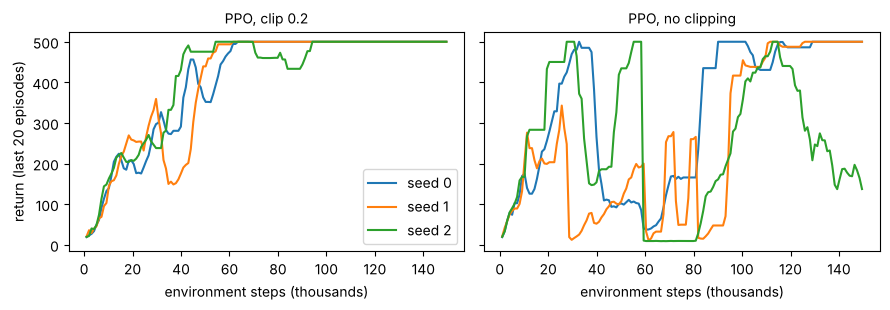

In [5]:
t0 = time.time()
for seed in [0, 1, 2]:
    runs["no clipping", seed], _ = ppo(clip=1e6, seed=seed)
    print(summary(f"no clipping, seed {seed}", runs["no clipping", seed]))
print(f"three runs took {time.time() - t0:.0f}s")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for a, name in zip(ax, ["clip 0.2", "no clipping"]):
    for seed in [0, 1, 2]:
        log = runs[name, seed]; a.plot(log[:, 0] / 1000, log[:, 1], label=f"seed {seed}")
    a.set_title(f"PPO, {name}", fontsize=10); a.set_xlabel("environment steps (thousands)")
ax[0].set_ylabel("return (last 20 episodes)"); ax[0].legend(); plt.tight_layout(); plt.show()

### 6. Monte Carlo tree search on tic-tac-toe
AlphaZero's search (Silver et al. 2018) repeats four steps: **select** a path down the tree with the PUCT rule, **expand** a new node, **evaluate** it, and **back up** the result. PUCT picks the move that maximizes

$Q(s, a) + c \cdot P(s, a) \cdot \dfrac{\sqrt{N(s)}}{1 + N(s, a)}$

where $Q$ is the average result of the move so far, $N$ counts visits, and $P$ is the network's prior. We have no network, so we use a uniform prior $P = 1/(\text{number of legal moves})$ and evaluate new nodes with one random game played to the end (a "rollout"; the original AlphaGo also used rollouts, played by a fast learned policy rather than at random). The move played is the most-visited one, and the share of visits for each move is what AlphaZero trains its policy network to predict.

In [6]:
LINES = [(0, 1, 2), (3, 4, 5), (6, 7, 8), (0, 3, 6), (1, 4, 7), (2, 5, 8), (0, 4, 8), (2, 4, 6)]
def winner(b):
    for i, j, k in LINES:
        if b[i] != 0 and b[i] == b[j] == b[k]: return b[i]
    return 0
def legal(b): return [i for i in range(9) if b[i] == 0]
def over(b): return winner(b) != 0 or not legal(b)
def play(b, m, p): b = list(b); b[m] = p; return tuple(b)          # boards are tuples of 9 cells: 1 = X, -1 = O, 0 = empty

class Node:
    def __init__(self, board, player):
        self.board, self.player, self.children, self.N, self.W = board, player, {}, 0, 0.0   # player = side to move

def rollout(b, player, rng):                                           # random play to the end: +1 X wins, -1 O wins, 0 draw
    b = list(b)
    while True:
        w = winner(b)
        if w: return w
        moves = [i for i in range(9) if b[i] == 0]
        if not moves: return 0
        b[rng.choice(moves)] = player; player = -player

def mcts(board, player, n_sim, rng, c=1.5):
    root = Node(board, player)
    for _ in range(n_sim):
        node, path = root, [root]
        while node.children:                                           # 1. select with PUCT (uniform prior)
            prior, sq = 1 / len(node.children), math.sqrt(node.N)
            node = max(node.children.values(), key=lambda ch: (ch.W / ch.N if ch.N else 0.0) + c * prior * sq / (1 + ch.N))
            path.append(node)
        if not over(node.board):                                       # 2. expand
            for m in legal(node.board): node.children[m] = Node(play(node.board, m, node.player), -node.player)
            node = rng.choice(list(node.children.values())); path.append(node)
        z = rollout(node.board, node.player, rng)                      # 3. evaluate
        for n in path:                                                 # 4. back up: value for the player who moved into n
            n.N += 1; n.W += z * (-n.player)
    return {m: ch.N for m, ch in root.children.items()}

def show_visits(board, player, n_sim, rng):
    v = mcts(board, player, n_sim, rng); total = sum(v.values())
    return np.array([[v.get(3 * r + c, 0) / total for c in range(3)] for r in range(3)])

rng = random.Random(0)
empty = show_visits((0,) * 9, 1, 1000, rng)
block = (1, 0, 0, -1, -1, 0, 1, 0, 0)                                  # X to move; O threatens to complete the middle row
must_block = show_visits(block, 1, 1000, rng)
print("visit shares from the empty board (X to move):\n", empty.round(2))
print("visit shares when X must block at the right of the middle row:\n", must_block.round(2))

visit shares from the empty board (X to move):
 [[0.16 0.03 0.04]
 [0.02 0.67 0.02]
 [0.01 0.   0.03]]
visit shares when X must block at the right of the middle row:
 [[0.   0.01 0.02]
 [0.   0.   0.95]
 [0.   0.01 0.01]]


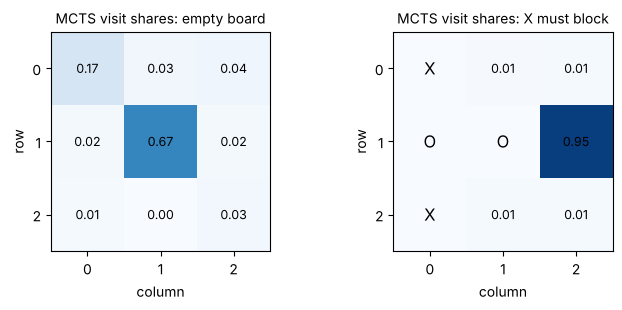

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(7, 3.2))
for a, (name, vis, b) in zip(ax, [("empty board", empty, (0,) * 9), ("X must block", must_block, block)]):
    a.imshow(vis, cmap="Blues", vmin=0, vmax=1)
    for i in range(9):
        r, c = divmod(i, 3)
        a.text(c, r, {1: "X", -1: "O", 0: f"{vis[r, c]:.2f}"}[b[i]], ha="center", va="center", fontsize=12 if b[i] else 9)
    a.set_title(f"MCTS visit shares: {name}", fontsize=10); a.set_xticks(range(3)); a.set_yticks(range(3))
    a.set_xlabel("column"); a.set_ylabel("row")
plt.tight_layout(); plt.show()

Now play games. Against a random player, MCTS plays 50 games as X and 50 as O. Then MCTS plays itself: tic-tac-toe is a draw with perfect play, so a strong player should draw against itself.

In [8]:
def game(x_agent, o_agent, rng):
    b, p = (0,) * 9, 1
    while not over(b):
        b = play(b, (x_agent if p == 1 else o_agent)(b, p, rng), p); p = -p
    return winner(b)

random_agent = lambda b, p, rng: rng.choice(legal(b))
def mcts_agent(n_sim):
    def agent(b, p, rng):
        visits = mcts(b, p, n_sim, rng)
        return max(visits, key=visits.get)                      # play the most-visited move
    return agent

t0 = time.time(); rng = random.Random(1)
for n_sim in [10, 100, 1000]:
    res = {"win": 0, "draw": 0, "loss": 0}
    for _ in range(50):
        w = game(mcts_agent(n_sim), random_agent, rng); res["win" if w == 1 else "loss" if w == -1 else "draw"] += 1
    for _ in range(50):
        w = game(random_agent, mcts_agent(n_sim), rng); res["win" if w == -1 else "loss" if w == 1 else "draw"] += 1
    print(f"MCTS with {n_sim:4d} simulations per move vs random, 100 games: {res}")
res = {"X wins": 0, "draws": 0, "O wins": 0}
for _ in range(20):
    w = game(mcts_agent(1000), mcts_agent(1000), rng); res["X wins" if w == 1 else "O wins" if w == -1 else "draws"] += 1
print(f"MCTS (1000) vs MCTS (1000), 20 games: {res}   ({time.time() - t0:.0f}s)")

MCTS with   10 simulations per move vs random, 100 games: {'win': 77, 'draw': 10, 'loss': 13}


MCTS with  100 simulations per move vs random, 100 games: {'win': 90, 'draw': 10, 'loss': 0}


MCTS with 1000 simulations per move vs random, 100 games: {'win': 94, 'draw': 5, 'loss': 1}


MCTS (1000) vs MCTS (1000), 20 games: {'X wins': 1, 'draws': 19, 'O wins': 0}   (4s)


### 7. PPO on Atari (NOT RUN here)
Atari games need a convolutional network, frame stacking and tens of millions of frames. CleanRL's single-file `ppo_atari.py`, which the Huang et al. 2022 post walks through detail by detail, is the easiest place to start.

In [ ]:
# NOT RUN: needs a GPU and `pip install "gymnasium[atari]>=1.0" ale-py` (each game takes hours to learn)
import gymnasium as gym, ale_py
gym.register_envs(ale_py)

def make_env():
    env = gym.make("ALE/Breakout-v5", frameskip=1)                       # let the wrapper below skip frames
    env = gym.wrappers.AtariPreprocessing(env, frame_skip=4, screen_size=84, grayscale_obs=True)
    return gym.wrappers.FrameStackObservation(env, stack_size=4)
envs = gym.vector.SyncVectorEnv([make_env for _ in range(8)])
obs, info = envs.reset(seed=0)
print(obs.shape)                                                         # (8, 4, 84, 84)
# Replace ActorCritic with a CNN (three conv layers, then a 512-unit layer) shared by the actor and the critic,
# keep the PPO update above, and log the episode returns from info. Compare clip 0.2 with clipping off over 3 seeds.

### 8. Exercises

In [9]:
# TODO: the gentle-step ablation. Repeat sections 4 and 5 with lr=1e-3 (three seeds each) and return a dict
# {"clip 0.2": [final returns], "no clipping": [final returns]}. Does clipping still matter when each update
# is small? Look at the share of ratios outside [0.8, 1.2] to explain your answer.
def gentle_ablation():
    return None          # replace with your code

res = gentle_ablation()
print("not done yet" if res is None else res)

not done yet


In [10]:
# TODO: AlphaZero in miniature. Play 200 games of MCTS (200 simulations) against itself and store, for every
# position, the board and the root visit shares. Train a small network (9 inputs, 9 outputs) to predict the
# visit shares, then use its output as the prior P in the PUCT rule. Return the win/draw/loss record against
# random play with only 20 simulations per move, with and without the learned prior.
def mini_alphazero():
    return None          # replace with your code

res = mini_alphazero()
print("not done yet" if res is None else res)

not done yet


### What to notice
(Written from the run above; your numbers will match if you keep the seeds.)

1. **CartPole is easy for a hand-written rule.** Random pushes lasted 22.7 steps on average, but the one-line rule "push toward the side the pole leans" scored the maximum, 500.0. CartPole tests whether a learning algorithm works; it is not a hard control problem.
2. **The GAE check passed**: with $\lambda = 1$ the advantages equal the discounted return minus $V$.
3. **PPO with clipping solved the task in all three seeds**: final return 500, and the lowest return in the second half of training was 500, 500 and 433. The seed-2 policy, acting greedily, scored 500.0 on 200 new episodes. Each update moved the policy a little: mean KL about 0.003, with 3.0–3.4% of probability ratios outside [0.8, 1.2].
4. **Without clipping, at the same deliberately large learning rate, training crashed.** Two seeds still ended at 500, but their returns fell as low as 166 and 15 in the second half, and the third ended at 137 after falling to 9. Each update moved the policy 12 to 30 times further (mean KL 0.033 to 0.085, with 9.0–24.5% of ratios outside [0.8, 1.2]). This is what clipping is for: it removes the incentive to push a ratio past $1 \pm \varepsilon$. We tested one learning rate only; the first exercise asks what happens with smaller steps, where clipping may matter much less (Engstrom et al. 2020 found that code-level details, rather than the core algorithm, explain most of PPO's gain over TRPO).
5. **MCTS visit counts are a better policy than its prior.** From the empty board 67% of visits went to the centre; when X had to block, 95% went to the blocking square. These visit shares are what AlphaZero trains its policy network to imitate.
6. **More search, stronger play, but random rollouts are noisy.** Against a random player MCTS scored 77 wins, 10 draws and 13 losses with 10 simulations per move, 90-10-0 with 100, and 94-5-1 with 1,000: even 1,000 simulations lost one game, because random rollouts misjudge some positions. Against itself it drew 19 of 20 games (tic-tac-toe is a draw with perfect play). AlphaZero replaces the rollouts with a learned value network.
7. These are tiny problems. CartPole and tic-tac-toe show the mechanics of PPO and MCTS, not how hard they are to tune on Atari, Go or language models.